# Week 9: Pandas and Visualization 
## Name: Bria Pickel-Fridman
## 10/26/2026

In [1]:
# Apache

import requests

base_url = "https://collectionapi.metmuseum.org"
search_path = "/public/collection/v1.1/search"
search_query = "?q=Apache" # the %20 stops the URL from breaking
artist_or_culture = "&artistOrCulture=true" # flag that limits results to the artist or culture fields
limit = "&limit=500" # sets the amount of responses per page to 500
offset = "&offset=0"

url = f'{base_url}{search_path}{search_query}{artist_or_culture}{limit}{offset}'
search_response = requests.get(url)

print(url)

https://collectionapi.metmuseum.org/public/collection/v1.1/search?q=Apache&artistOrCulture=true&limit=500&offset=0


In [2]:
print(search_response.ok)

True


In [3]:
apache_objects = search_response.json()
complete_apache_objects = apache_objects["objectIDs"]
print(len(complete_apache_objects))
print ("out of")
print(apache_objects['total'])
print(complete_apache_objects[0])

41
out of
41
310598


In [4]:
# Fix: Create a shallow copy of the list so they remain separate, 
# then pop the first item from the new list.
edited_complete_apache_objects = complete_apache_objects.copy()
removed_id = edited_complete_apache_objects.pop(0) 

# Outputs will no longer match
print(complete_apache_objects[0])          # Original first ID
print(edited_complete_apache_objects[0])   # The new first ID (old index 1)
print(len(edited_complete_apache_objects))  # This will now successfully print the length (1 less than original)

310598
312503
40


In [7]:
from time import sleep 

object_path = "/public/collection/v1/objects/" 
all_apache_details = []

for apache_artwork in edited_complete_apache_objects:
    url = f"{base_url}{object_path}{apache_artwork}"
    response_object = requests.get(url) 
    
    # Check if the API request was successful (status code 200)
    if response_object.ok:
        all_apache_details.append(response_object.json())
        print(f"grabbed details from objectID {apache_artwork} with status code {response_object.status_code}")
    else:
        # If it's a 404 or any other error, skip it and don't append it to the list
        print(f"⚠️ SKIPPED objectID {apache_artwork} - Received status code {response_object.status_code}")
        
    sleep(0.5) 

print(f"Total valid objects captured: {len(all_apache_details)}") 
if all_apache_details:
    print(all_apache_details[0])

grabbed details from objectID 312503 with status code 200
grabbed details from objectID 318353 with status code 200
grabbed details from objectID 319204 with status code 200
grabbed details from objectID 501189 with status code 200
grabbed details from objectID 501191 with status code 200
grabbed details from objectID 501194 with status code 200
grabbed details from objectID 501216 with status code 200
grabbed details from objectID 501220 with status code 200
grabbed details from objectID 502293 with status code 200
grabbed details from objectID 502369 with status code 200
grabbed details from objectID 502375 with status code 200
grabbed details from objectID 502376 with status code 200
grabbed details from objectID 502546 with status code 200
grabbed details from objectID 502547 with status code 200
grabbed details from objectID 502552 with status code 200
grabbed details from objectID 502627 with status code 200
grabbed details from objectID 502760 with status code 200
grabbed detail

In [8]:
import csv   # brings in all the csv-related functions

with open("all_apache_artworks.csv", "w", encoding="utf-8") as file: # initiate the opening of a file, and write a new file
    writer = csv.DictWriter(file, all_apache_details[0].keys()) # this creates the columns in the CSV file from the keys
    writer.writeheader() # Creates the first row of the CSV, containing the HEaders
    writer.writerows(all_apache_details) # goes through every item in the yoko_ono_artworks list and put it in the CSV file
    # you should see it in your folder after running.

### filter your dataset according to a specific term using the == operator or the str.contains method (using filtering criteria different from those used in class if using the MET dataset)

In [1]:
import pandas as pd  # this imports the pandas library under the nickname 'pd' which is used in a lot of online documentation

In [2]:
# we first create a dataframe (df) using the read_csv() method

df = pd.read_csv('all_apache_artworks.csv') # df is the variable that holds my dataframe

In [4]:
df.head(3) # head gives me the first items in the dataframe. the argument is how many items to display

,objectID,isHighlight,accessionNumber,accessionYear,isPublicDomain,primaryImage,primaryImageSmall,additionalImages,constituents,department,...,classification,rightsAndReproduction,linkResource,metadataDate,repository,objectURL,tags,objectWikidata_URL,isTimelineWork,GalleryNumber
0,312503,False,1979.206.923,1979,False,NaN,NaN,[],NaN,The Michael C. Rockefeller Wing,...,Basketry-Containers,NaN,NaN,2025-10-11T04:50:34.32Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
1,318353,False,1999.484.10,1999,True,https://images.metmuseum.org/CRDImages/ao/orig...,https://images.metmuseum.org/CRDImages/ao/web-...,['https://images.metmuseum.org/CRDImages/ao/or...,NaN,The Michael C. Rockefeller Wing,...,Hide-Costumes,NaN,NaN,2025-12-20T04:50:39.43Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Human Figures', 'AAT_URL': 'http://...",NaN,False,NaN
2,319204,False,"2011.154.170a, b",2011,False,NaN,NaN,[],NaN,The American Wing,...,NaN,NaN,NaN,2025-01-30T04:54:21.21Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Human Figures', 'AAT_URL': 'http://...",NaN,False,NaN


In [6]:
title_counts = df.value_counts('title')[:15]
title_counts

title
Tsii' Edo' Ai (Apache Fiddle)             11
Rattle                                     4
End-blown flute                            3
Drum                                       3
Flute                                      2
Bow and Arrows with Quiver and Bowcase     1
Bone Whistle                               1
Bladder Rattle                             1
Basket Tray                                1
Basket                                     1
Flute (end blown flute)                    1
Ceremonial Robe                            1
Disc Rattle                                1
Mystery Flute (Tohono O'odham style)       1
Frame Drum                                 1
Name: count, dtype: int64

In [5]:
# getting rid of unwnted columns

unwanted_columns = ['primaryImageSmall', 'portfolio', 'artistRole', 'artistPrefix', 'artistSuffix', 'artistAlphaSort', 'subregion', 'locale', 'locus', 'excavation', 'river', 'classification', 'rightsAndReproduction', 'linkResource', 'metadataDate', 'repository']

for column in unwanted_columns:
    df = df.drop(column, axis=1)

df.head(3)

,objectID,isHighlight,accessionNumber,accessionYear,isPublicDomain,primaryImage,additionalImages,constituents,department,objectName,...,city,state,county,country,region,objectURL,tags,objectWikidata_URL,isTimelineWork,GalleryNumber
0,312503,False,1979.206.923,1979,False,NaN,[],NaN,The Michael C. Rockefeller Wing,Basket,...,San Carlos area,Arizona,NaN,United States,NaN,https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
1,318353,False,1999.484.10,1999,True,https://images.metmuseum.org/CRDImages/ao/orig...,['https://images.metmuseum.org/CRDImages/ao/or...,NaN,The Michael C. Rockefeller Wing,Robe,...,NaN,NaN,NaN,United States,NaN,https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Human Figures', 'AAT_URL': 'http://...",NaN,False,NaN
2,319204,False,"2011.154.170a, b",2011,False,NaN,[],NaN,The American Wing,Basket,...,NaN,Arizona,NaN,United States,NaN,https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Human Figures', 'AAT_URL': 'http://...",NaN,False,NaN


In [8]:
df.columns

Index(['objectID', 'isHighlight', 'accessionNumber', 'accessionYear',
       'isPublicDomain', 'primaryImage', 'additionalImages', 'constituents',
       'department', 'objectName', 'title', 'culture', 'period', 'dynasty',
       'reign', 'artistDisplayName', 'artistDisplayBio', 'artistNationality',
       'artistBeginDate', 'artistEndDate', 'artistGender',
       'artistWikidata_URL', 'artistULAN_URL', 'objectDate', 'objectBeginDate',
       'objectEndDate', 'medium', 'dimensions', 'measurements', 'creditLine',
       'geographyType', 'city', 'state', 'county', 'country', 'region',
       'objectURL', 'tags', 'objectWikidata_URL', 'isTimelineWork',
       'GalleryNumber'],
      dtype='object')

In [10]:
df.value_counts('medium')

medium
Agave flower stalk, sinew, horsehair, pitch, sinew                       1
Agave flower stalk, wood, paint, horsehair                               1
Agave stalk, horsehair, gut                                              1
Agave stalk, paint, horsehair                                            1
Agave stalk, sinew, paint, horsehair                                     1
Agave, horsehair, sinew, wood                                            1
Agave, wood, sinew, horsehair                                            1
Cane (willow, black devil's claw), pinon tar                             1
Cane, red and blue stain                                                 1
Hide, wood, pebbles(?), cord, tin, buckskin, polychrome                  1
Iron, skin, cord                                                         1
Iron, wood, leather, feathers                                            1
Metal, hide                                                              1
Native-tanned leat

In [15]:
wood = df['medium'].str.contains("wood", case=False, na=False) # modified to not be case sensitive

df[wood]

,objectID,isHighlight,accessionNumber,accessionYear,isPublicDomain,primaryImage,additionalImages,constituents,department,objectName,...,city,state,county,country,region,objectURL,tags,objectWikidata_URL,isTimelineWork,GalleryNumber
4,501191,False,89.4.575,1889,True,https://images.metmuseum.org/CRDImages/mi/orig...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,Flute (end blown flute),...,NaN,NaN,NaN,United States,NaN,https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
5,501194,False,89.4.578,1889,True,https://images.metmuseum.org/CRDImages/mi/orig...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,Flute,...,NaN,Arizona & New Mexico,NaN,United States,NaN,https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
6,501216,False,"89.4.600a, b",1889,True,https://images.metmuseum.org/CRDImages/mi/orig...,['https://images.metmuseum.org/CRDImages/mi/or...,"[{'constituentID': 219864, 'role': 'Maker', 'n...",Musical Instruments,Tsii' Edo' Ai,...,NaN,NaN,NaN,United States,Southwest,https://www.metmuseum.org/art/collection/searc...,NaN,https://www.wikidata.org/wiki/Q116412969,False,NaN
7,501220,False,"89.4.604a, b",1889,True,https://images.metmuseum.org/CRDImages/mi/orig...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,Tsii' Edo' Ai,...,NaN,NaN,NaN,United States,NaN,https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
8,502293,False,"89.4.1746a, b",1889,True,https://images.metmuseum.org/CRDImages/mi/orig...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,Tsii' Edo' Ai,...,NaN,NaN,NaN,United States,NaN,https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
10,502375,False,"89.4.2924a, b",1889,False,NaN,[],NaN,Musical Instruments,Tsii' Edo' Ai,...,NaN,Arizona or New Mexico,NaN,United States,NaN,https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
11,502376,False,"89.4.2925a, b",1889,False,NaN,[],NaN,Musical Instruments,Tsii' Edo' Ai,...,NaN,Arizona or New Mexico,NaN,United States,NaN,https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
16,502760,False,89.4.2630,1889,False,NaN,[],NaN,Musical Instruments,Bone Whistle,...,NaN,"Arizona, New Mexico, or Texas",NaN,United States,NaN,https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
17,502761,True,"89.4.2631a, b",1889,True,https://images.metmuseum.org/CRDImages/mi/orig...,['https://images.metmuseum.org/CRDImages/mi/or...,"[{'constituentID': 155495, 'role': 'Maker', 'n...",Musical Instruments,Tsii 'Edo' a'tl,...,NaN,Arizona,NaN,United States,NaN,https://www.metmuseum.org/art/collection/searc...,NaN,https://www.wikidata.org/wiki/Q104413041,False,NaN
18,502763,False,"89.4.2675a, b",1889,False,NaN,[],NaN,Musical Instruments,Frame Drum,...,Fort Sill?,Oklahoma,NaN,United States,NaN,https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN


### create a simple graph of your dataset using the df.plot() method (plotting a different aspect of the dataset than the ones we looked at in class, if using the MET set)

<Axes: ylabel='department'>

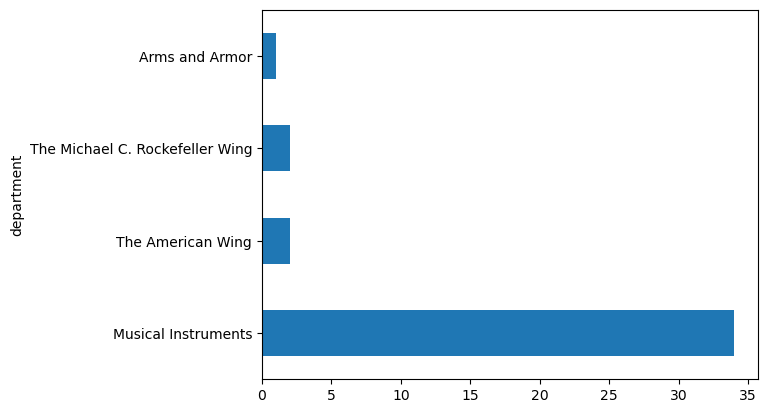

In [16]:
df.value_counts('department').plot(kind = 'barh')

<Axes: title={'center': 'Apache artworks in the collection'}, ylabel='artist name'>

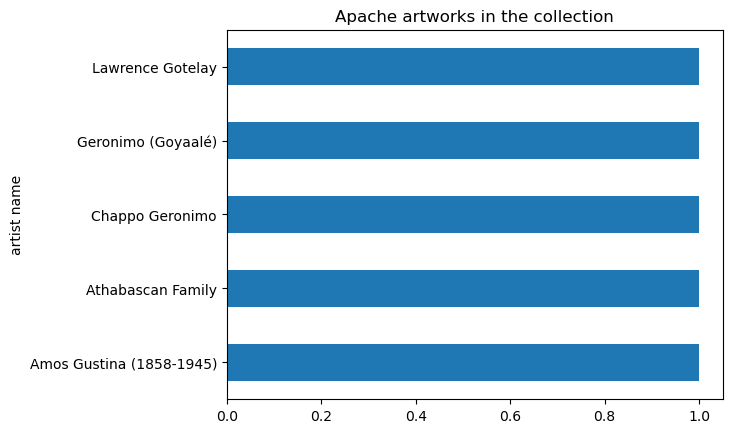

In [17]:
df.value_counts('artistDisplayName').nlargest(10).plot(kind = 'barh', ylabel='artist name', title='Apache artworks in the collection')

In [ ]:
df.value_counts('s').nlargest(10).plot(kind = 'barh', ylabel='artist name', title='Apache artworks in the collection')